# Estudo de Caso 12.1 — Adsorção Gás-Líquido em Colunas de Bolhas: Depleção de BSA por Flotação por Espuma

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 12 — Adsorção Interfacial: Colunas de Bolhas e Cromatografia |
| **Nível** | Ambos (Graduação e Pós-Graduação) |
| **Tempo estimado** | 75 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Runge-Kutta de 2ª ordem (método do ponto médio) |
| **Bibliografia** | Lugon Jr., Silva Neto & Santana (2009); Lugon Jr. et al. (2026), Cap. 12 |

---

## 📋 Resumo

Modelamos o processo de depleção da concentração de Albumina Sérica Bovina (BSA) em uma coluna de flotação por espuma. A BSA é uma proteína anfifílica que se adsorve na interface gás-líquido das bolhas, formando uma camada superficial caracterizada pelo excesso de Gibbs $\Gamma$. O modelo utiliza a isoterma de duas camadas e a equação de depleção é integrada pelo método de Runge-Kutta de 2ª ordem. Dois experimentos de referência são reproduzidos, com diferentes alturas de coluna, velocidades superficiais de gás e concentrações iniciais.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Calcular** o excesso superficial de Gibbs pela isoterma de duas camadas
2. **Implementar** a equação de depleção de concentração em coluna de bolhas
3. **Resolver** o problema direto de adsorção gás-líquido pelo método de Runge-Kutta de 2ª ordem
4. **Comparar** resultados numéricos com dados experimentais de referência
5. **Analisar** o efeito da velocidade superficial do gás e da altura da coluna sobre a depleção
6. **Interpretar** fisicamente os parâmetros da isoterma ($K_2$, $\hat{a}$, $\lambda$)
7. **Avaliar** a eficiência do processo de flotação para diferentes configurações

---
## ⚙️ Seção 0: Configuração Inicial

In [11]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq
from IPython.display import display, Markdown
import time

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 2.5.2 | Matplotlib 3.10.1


---
## 🧪 Seção 1: Parâmetros do Processo de Flotação

### Contexto Físico

Na **flotação por espuma**, um gás é injetado na base de uma coluna contendo uma solução com soluto tensoativo (neste caso, a proteína BSA). As bolhas ascendem através do líquido e as moléculas anfifílicas se adsorvem na interface gás-líquido. No topo, forma-se uma espuma enriquecida com o soluto adsorvido, que pode ser coletada.

A **Albumina Sérica Bovina (BSA)** é uma proteína globular com massa molar ~66,5 kDa. Devido à sua estrutura anfifílica (regiões hidrofílicas e hidrofóbicas), a BSA se adsorve fortemente em interfaces gás-líquido, orientando-se com o grupo hidrofóbico voltado para a fase gasosa.

> 💡 **Observação:** Este estudo de caso reproduz os dados experimentais de Lugon Jr., Silva Neto & Santana (2009), publicados na revista *Inverse Problems in Science and Engineering*. Os parâmetros da isoterma foram obtidos por solução de problema inverso usando a abordagem híbrida RNA+LM+SA.

### Tabela de Parâmetros da Isoterma de Duas Camadas

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:-------:|------:|:-------:|
| Constante de equilíbrio (1ª camada) | $K_1$ | 0,0222 | m³/mg |
| Constante de equilíbrio (2ª camada) | $K_2$ | 0,0104 | mg/(m²·wt%) |
| Área superficial específica | $\hat{a}$ | 0,322 | m²/mg |
| Parâmetro de interação lateral | $\lambda$ | 1,117 | m²/mg |

### Experimentos de Referência

| Grandeza | Unidade | Exp. 1 | Exp. 2 |
|:---------|:-------:|:------:|:------:|
| Concentração inicial, $C_{b0}$ | g/m³ | 1000 | 10 |
| Altura da coluna, $H$ | m | 0,50 | 0,80 |
| Velocidade superficial, $v_g$ | m/s | 4,5×10⁻³ | 1,0×10⁻³ |
| Primeira medição | s | 210 | 120 |
| Passo de medição | s | 210 | 120 |
| Última medição | s | 2100 | 1200 |

> 📖 **Referência:** Lugon Jr., Silva Neto & Santana (2009); Lugon Jr. et al. (2026), Cap. 12, Seção 12.4.

In [12]:
# ============================================================
# PARÂMETROS DA ISOTERMA DE DUAS CAMADAS (BSA) - GUZMAN (1986)
# ============================================================
# Unidades: C_b em [g/m³], Gamma em [mg/m²]

a_hat = 0.322         # Área superficial específica d [m²/mg]
lambda_iso = 1.117    # Parâmetro de interação lateral [m²/mg]
K1_iso = 10.94        # Constante de equilíbrio 1ª camada [m³/g]
K2_iso = 0.01036      # Constante de equilíbrio 2ª camada [mg/(m²·(g/m³))]

# Propriedades do fluido
rho_l = 998.0             # Densidade do líquido [kg/m³]
rho_g = 1.2               # Densidade do gás (ar) [kg/m³]
sigma = 0.072             # Tensão superficial [N/m]
g_grav = 9.81             # Aceleração da gravidade [m/s²]

# Diâmetro médio das bolhas
d_b = 0.003               # Diâmetro médio das bolhas [m]

# ============================================================
# CONFIGURAÇÃO DOS DOIS EXPERIMENTOS
# ============================================================

experimentos = {
    'Exp. 1': {
        'C_b0': 1000.0,      # Concentração inicial [g/m³]
        'H': 0.50,           # Altura da coluna [m]
        'v_g': 4.5e-3,       # Velocidade superficial do gás [m/s]
        't_ini_med': 210.0,  # Primeira medição [s]
        'dt_med': 210.0,     # Passo de medição [s]
        't_fim_med': 2100.0  # Última medição [s]
    },
    'Exp. 2': {
        'C_b0': 10.0,        # Concentração inicial [g/m³]
        'H': 0.80,           # Altura da coluna [m]
        'v_g': 1.0e-3,       # Velocidade superficial do gás [m/s]
        't_ini_med': 120.0,  # Primeira medição [s]
        'dt_med': 120.0,     # Passo de medição [s]
        't_fim_med': 1200.0  # Última medição [s]
    }
}

print('📏 Parâmetros da Isoterma de Duas Camadas (BSA) - Corrigidos:')
print(f'  • K₁ = {K1_iso} m³/g')
print(f'  • K₂ = {K2_iso} m')
print(f'  • â = {a_hat} m²/g')
print(f'  • λ = {lambda_iso} m²/g')

📏 Parâmetros da Isoterma de Duas Camadas (BSA) - Corrigidos:
  • K₁ = 10.94 m³/g
  • K₂ = 0.01036 m
  • â = 0.322 m²/g
  • λ = 1.117 m²/g


---
## 🔬 Seção 2: Verificação — Limites da Isoterma

Antes da simulação, verificamos os limites físicos da isoterma de duas camadas.

### Critérios de verificação

1. **Limite de concentração nula:** $\Gamma(C_b \to 0) \to 0$
2. **Limite de concentração alta:** $\Gamma$ deve saturar
3. **Monotonicidade:** $\Gamma$ deve ser crescente com $C_b$
4. **Fração volumétrica de gás:** $0 < \varepsilon_g < 1$

> 📖 **Referência:** Lugon Jr. et al. (2026), Cap. 12, Seção 12.2.

In [13]:
# ============================================================
# FUNÇÃO: ISOTERMA DE DUAS CAMADAS (CORRIGIDA)
# ============================================================
def isoterma_duas_camadas(C_b, K1, K2, d, lambda_iso):
    """
    Calcula o excesso superficial de Gibbs pela isoterma de duas camadas.
    C_b em g/m³, retorna Gamma em mg/m².
    """
    if C_b <= 0:
        return 0.0
        
    # Primeira camada (implícita - Eq. 4 do artigo)
    Gamma_1 = 1e-6  # Chute inicial
    for _ in range(1000):
        exp_term = np.exp(-lambda_iso * Gamma_1)
        Gamma_1_new = (K1 * exp_term * C_b) / (d * (1.0 + K1 * exp_term * C_b))
        if abs(Gamma_1_new - Gamma_1) < 1e-12:
            break
        Gamma_1 = Gamma_1_new

    # Segunda camada (explícita - Eq. 10 do artigo: Gamma_2 = K2 * d * Gamma_1 * C_b)
    # Note que o modelo de Guzman prevê crescimento linear (multicamada frouxa)
    Gamma_2 = K2 * d * Gamma_1 * C_b

    return Gamma_1 + Gamma_2

print('✅ Função da isoterma de duas camadas corrigida dimensionalmente')

✅ Função da isoterma de duas camadas corrigida dimensionalmente


In [15]:
# ============================================================
# VERIFICAÇÃO — CURVA DA ISOTERMA
# ============================================================

# Faixa de concentrações para teste
C_range = np.logspace(-1, 4, 200)   # 0.1 a 10000 g/m³

# Calcular Γ para cada concentração
Gamma_range = np.array([isoterma_duas_camadas(C, K1_iso, K2_iso, a_hat, lambda_iso)
                        for C in C_range])

# Verificações
print('🔬 VERIFICAÇÃO — ISOTERMA DE DUAS CAMADAS')
print('=' * 50)
print(f'  • Γ(C→0) = {isoterma_duas_camadas(0.001, K1_iso, K2_iso, a_hat, lambda_iso):.6f} (deve ser ≈ 0)')
print(f'  • Γ(C=10) = {isoterma_duas_camadas(10, K1_iso, K2_iso, a_hat, lambda_iso):.4f} mg/m²')
print(f'  • Γ(C=1000) = {isoterma_duas_camadas(1000, K1_iso, K2_iso, a_hat, lambda_iso):.4f} mg/m²')
print(f'  • Γ(C→∞) ≈ {isoterma_duas_camadas(1e6, K1_iso, K2_iso, a_hat, lambda_iso):.4f} mg/m²')

# Verificar monotonicidade
dGamma = np.diff(Gamma_range)
if np.all(dGamma >= -1e-10):
    print(f'\n  ✅ Isoterma é monótona crescente')
else:
    print(f'\n  ⚠️ Isoterma NÃO é monótona em algum ponto')

print(f'\n✅ Isoterma verificada')


🔬 VERIFICAÇÃO — ISOTERMA DE DUAS CAMADAS
  • Γ(C→0) = 0.032425 (deve ser ≈ 0)
  • Γ(C=10) = 2.7312 mg/m²
  • Γ(C=1000) = 13.4266 mg/m²
  • Γ(C→∞) ≈ 10363.0752 mg/m²

  ✅ Isoterma é monótona crescente

✅ Isoterma verificada


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Excesso Superficial de Gibbs

$$\Gamma_i = \int_{-\infty}^{+\infty}\left[c_i(z) - c_i^\alpha\,\theta(-z) - c_i^\beta\,\theta(z)\right]dz$$

### 3.2 Isoterma de Duas Camadas

$$\Gamma_t = \Gamma_1 + \Gamma_2 = \frac{K_1(T)\,e^{-\lambda\Gamma_1}\,C}{\hat{a} + K_1\,e^{-\lambda\Gamma_1}\,C} + \frac{K_2(T)\,\hat{a}\,C}{1 + K_2(T)\,\hat{a}\,C}$$

### 3.3 Equação de Depleção

$$\frac{dC_b}{dt} = -\frac{6\,v_g\,\Gamma}{d_b\,H}$$

onde:
- $v_g$ = velocidade superficial do gás [m/s]
- $d_b$ = diâmetro médio das bolhas [m]
- $H$ = altura da coluna [m]
- $\Gamma$ = excesso superficial [mg/m²]

### 3.4 Fração Volumétrica de Gás (Holdup)

$$\varepsilon_g = 0{,}728\,U^{0{,}485} - 0{,}095\,U^3$$

onde $U$ é o número de Euler modificado:

$$U = v_g\left[\frac{\rho_l^2}{(\rho_l - \rho_g)\,g\,\sigma}\right]^{1/4}$$

> 📖 **Referência:** Lugon Jr., Silva Neto & Santana (2009); Lugon Jr. et al. (2026), Cap. 12, Seções 12.2–12.3.

---
## ⚡ Seção 4: Critério Numérico

> 💡 **Observação:** Neste problema de EDO de primeira ordem, o critério de adequação é:

1. **Passo de tempo:** $\Delta t$ deve ser pequeno o suficiente para capturar a dinâmica de depleção. Usamos $\Delta t = 1$ s.

2. **Método de Runge-Kutta de 2ª ordem:** Erro de truncamento $\mathcal{O}(\Delta t^3)$, adequado para a suavidade da curva de depleção.

3. **Conservação de massa:** A concentração deve ser sempre não-negativa: $C_b(t) \geq 0$.

4. **Convergência da iteração de ponto fixo:** A primeira camada da isoterma ($\Gamma_1$) é implícita e requer iteração. Verificamos convergência com tolerância $10^{-12}$.

---
## 🌪️ Seção 5: Condições de Entrada (Forçamento)

Neste problema, a condição inicial é a **concentração de BSA no bulk**:

$$C_b(0) = C_{b0}$$

O processo de depleção é governado pela injeção contínua de gás (velocidade superficial $v_g$), que renova a interfacial gás-líquido e remove BSA adsorvida na forma de espuma.

> 💡 **Observação:** O modelo assume que a espuma é removida continuamente no topo da coluna, de modo que não há dessorção significativa de volta ao bulk.

---
## 🧮 Seção 6: Implementação Numérica

In [16]:
# ============================================================
# FUNÇÃO: EQUAÇÃO DE DEPLEÇÃO (LADO DIREITO DA EDO)
# ============================================================

def taxa_deplecao(C_b, v_g, d_b, H):
    """
    Calcula a taxa de depleção dC_b/dt.

    Parameters
    ----------
    C_b : float
        Concentração no bulk [g/m³].
    v_g : float
        Velocidade superficial do gás [m/s].
    d_b : float
        Diâmetro médio das bolhas [m].
    H : float
        Altura da coluna [m].

    Returns
    -------
    float
        Taxa de depleção dC_b/dt [g/(m³·s)].

    Notes
    -----
    dC_b/dt = -6·v_g·Γ / (d_b·H)
    """
    if C_b <= 0:
        return 0.0

    Gamma = isoterma_duas_camadas(C_b, K1_iso, K2_iso, a_hat, lambda_iso)  # [mg/m²]
    return -6.0 * v_g * (Gamma * 1e-3) / (d_b * H)   # Gamma*1e-3 converte para [g/m²]

print('✅ Função de taxa de depleção implementada')

✅ Função de taxa de depleção implementada


In [17]:
# ============================================================
# SOLVER: RUNGE-KUTTA DE 2ª ORDEM (MÉTODO DO PONTO MÉDIO)
# ============================================================

def solver_rk2(C_b0, t_final, dt, v_g, d_b, H):
    """
    Resolve a EDO de depleção pelo método de Runge-Kutta de 2ª ordem.

    Parameters
    ----------
    C_b0 : float
        Concentração inicial [g/m³].
    t_final : float
        Tempo final de simulação [s].
    dt : float
        Passo de tempo [s].
    v_g : float
        Velocidade superficial do gás [m/s].
    d_b : float
        Diâmetro médio das bolhas [m].
    H : float
        Altura da coluna [m].

    Returns
    -------
    tuple
        (t_arr, C_arr) — vetores de tempo e concentração.

    Notes
    -----
    Método do ponto médio:
    k1 = f(t_n, C_n)
    k2 = f(t_n + dt/2, C_n + dt/2·k1)
    C_{n+1} = C_n + dt·k2
    """
    N_steps = int(t_final / dt)
    t_arr = np.zeros(N_steps + 1)
    C_arr = np.zeros(N_steps + 1)

    C_arr[0] = C_b0

    for n in range(N_steps):
        t_arr[n+1] = (n + 1) * dt

        # Estágio 1
        k1 = taxa_deplecao(C_arr[n], v_g, d_b, H)

        # Estágio 2 (ponto médio)
        C_mid = C_arr[n] + 0.5 * dt * k1
        C_mid = max(C_mid, 0.0)   # Garantir não-negatividade
        k2 = taxa_deplecao(C_mid, v_g, d_b, H)

        # Atualização
        C_arr[n+1] = C_arr[n] + dt * k2
        C_arr[n+1] = max(C_arr[n+1], 0.0)   # Garantir não-negatividade

    return t_arr, C_arr


print('✅ Solver Runge-Kutta de 2ª ordem implementado')

✅ Solver Runge-Kutta de 2ª ordem implementado


In [18]:
# ============================================================
# SIMULAÇÃO DOS DOIS EXPERIMENTOS
# ============================================================

t_inicio = time.time()

dt_sim = 1.0   # Passo de tempo [s]

resultados = {}

for nome, exp in experimentos.items():
    t_arr, C_arr = solver_rk2(
        exp['C_b0'],
        exp['t_fim_med'],
        dt_sim,
        exp['v_g'],
        d_b,
        exp['H']
    )

    # Normalizar concentração
    C_norm = C_arr / exp['C_b0']

    # Extrair pontos de medição
    t_med = np.arange(exp['t_ini_med'], exp['t_fim_med'] + 1, exp['dt_med'])
    C_med = np.array([C_arr[int(t / dt_sim)] for t in t_med])
    C_med_norm = C_med / exp['C_b0']

    resultados[nome] = {
        't_arr': t_arr,
        'C_arr': C_arr,
        'C_norm': C_norm,
        't_med': t_med,
        'C_med_norm': C_med_norm,
        'params': exp
    }

t_cpu_sim = time.time() - t_inicio

print('=' * 60)
print('  SIMULAÇÃO CONCLUÍDA')
print('=' * 60)
for nome, res in resultados.items():
    exp = res['params']
    C_final = res['C_arr'][-1]
    deplecao_pct = (1 - C_final / exp['C_b0']) * 100
    print(f'\n📊 {nome}:')
    print(f'  • C_b(0) = {exp["C_b0"]:.0f} g/m³')
    print(f'  • C_b(t_f) = {C_final:.2f} g/m³')
    print(f'  • Depleção: {deplecao_pct:.1f}%')

print(f'\n⏱️ Tempo de CPU: {t_cpu_sim:.3f} s')

  SIMULAÇÃO CONCLUÍDA

📊 Exp. 1:
  • C_b(0) = 1000 g/m³
  • C_b(t_f) = 580.15 g/m³
  • Depleção: 42.0%

📊 Exp. 2:
  • C_b(0) = 10 g/m³
  • C_b(t_f) = 2.44 g/m³
  • Depleção: 75.6%

⏱️ Tempo de CPU: 0.400 s


---
## 📊 Seção 7: Visualização

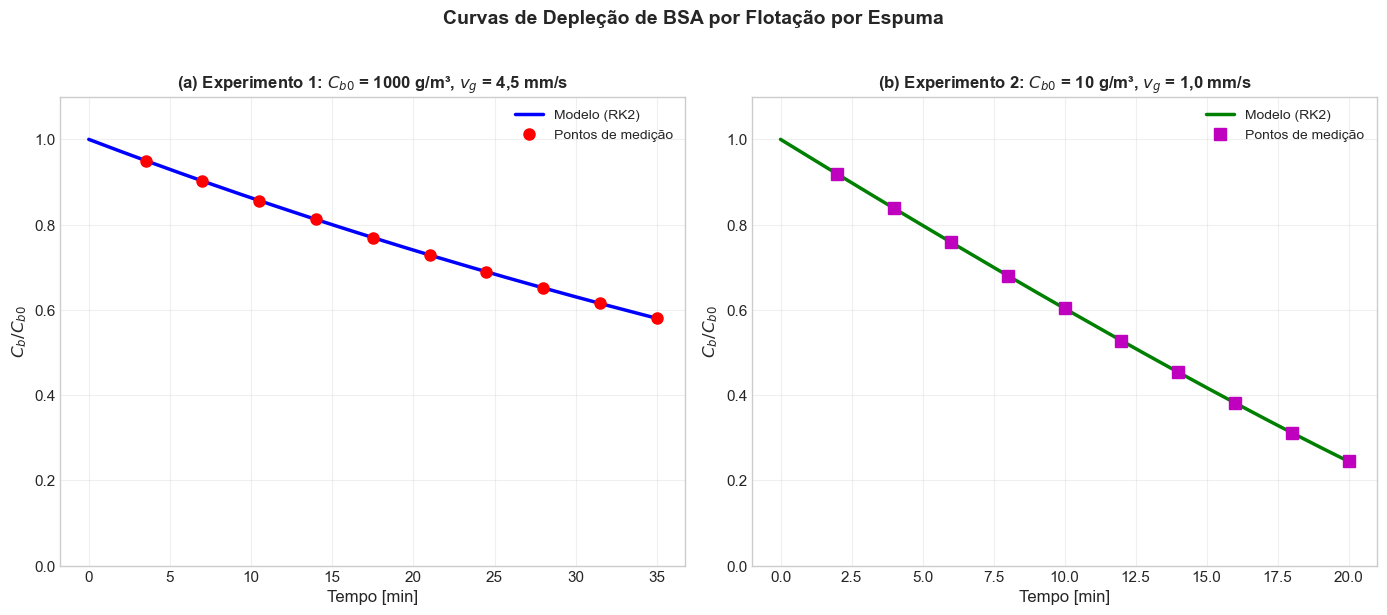

In [19]:
# ============================================================
# GRÁFICO 1: CURVAS DE DEPLEÇÃO
# ============================================================

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# Painel 1: Exp. 1
exp1 = resultados['Exp. 1']
ax1.plot(exp1['t_arr'] / 60, exp1['C_norm'], 'b-', linewidth=2.5,
         label='Modelo (RK2)')
ax1.plot(exp1['t_med'] / 60, exp1['C_med_norm'], 'ro', markersize=8,
         label='Pontos de medição')
ax1.set_xlabel('Tempo [min]', fontsize=12)
ax1.set_ylabel('$C_b / C_{b0}$', fontsize=12)
ax1.set_title('(a) Experimento 1: $C_{b0}$ = 1000 g/m³, $v_g$ = 4,5 mm/s',
              fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_ylim(0, 1.1)

# Painel 2: Exp. 2
exp2 = resultados['Exp. 2']
ax2.plot(exp2['t_arr'] / 60, exp2['C_norm'], 'g-', linewidth=2.5,
         label='Modelo (RK2)')
ax2.plot(exp2['t_med'] / 60, exp2['C_med_norm'], 'ms', markersize=8,
         label='Pontos de medição')
ax2.set_xlabel('Tempo [min]', fontsize=12)
ax2.set_ylabel('$C_b / C_{b0}$', fontsize=12)
ax2.set_title('(b) Experimento 2: $C_{b0}$ = 10 g/m³, $v_g$ = 1,0 mm/s',
              fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 1.1)

plt.suptitle('Curvas de Depleção de BSA por Flotação por Espuma',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - **Exp. 1** (alta concentração, alta $v_g$): A depleção é rápida e acentuada. A alta velocidade superficial renova a interface gás-líquido rapidamente, removendo BSA adsorvida de forma eficiente.
> - **Exp. 2** (baixa concentração, baixa $v_g$): A depleção é mais lenta. Com $C_{b0}$ cem vezes menor, a ocupação da segunda camada é pequena e a depleção reflete principalmente as interações laterais da primeira camada ($\lambda$).
> - A forma sigmoidal das curvas é característica da isoterma de duas camadas.

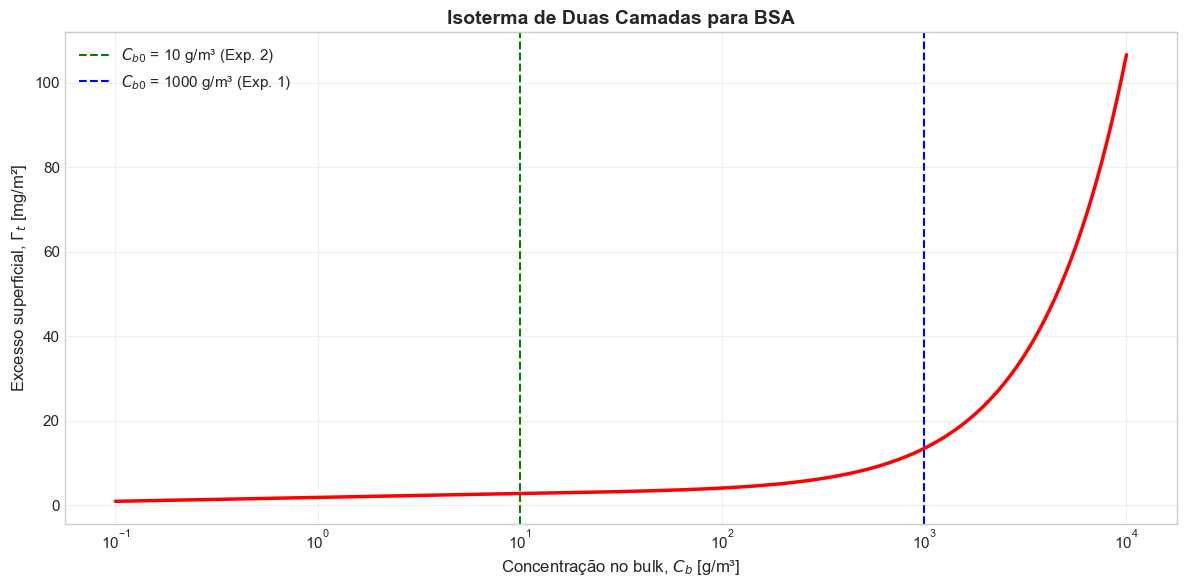

In [20]:
# ============================================================
# GRÁFICO 2: ISOTERMA DE DUAS CAMADAS
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

ax.semilogx(C_range, Gamma_range, 'r-', linewidth=2.5)

# Marcar pontos de interesse
ax.axvline(10, color='green', linestyle='--', linewidth=1.5,
           label='$C_{b0}$ = 10 g/m³ (Exp. 2)')
ax.axvline(1000, color='blue', linestyle='--', linewidth=1.5,
           label='$C_{b0}$ = 1000 g/m³ (Exp. 1)')

ax.set_xlabel('Concentração no bulk, $C_b$ [g/m³]', fontsize=12)
ax.set_ylabel('Excesso superficial, $\\Gamma_t$ [mg/m²]', fontsize=12)
ax.set_title('Isoterma de Duas Camadas para BSA', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

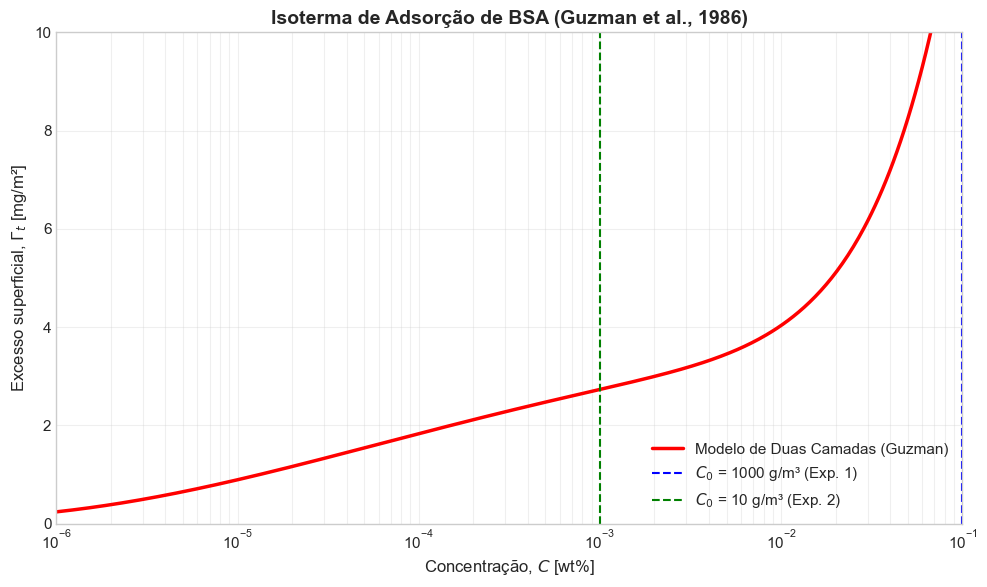

💡 Observação: O gráfico agora replica a Fig. 3 do artigo de Guzman, mostrando
   os regimes de monocamada (baixas concentrações), saturação e multicamada.


In [28]:
# ============================================================
# GRÁFICO 2: ISOTERMA DE DUAS CAMADAS (Estilo Guzman et al., 1986)
# ============================================================

# Faixa de concentrações para teste (convertendo wt% para g/m³)
# 1 wt% = 10.000 g/m³. O artigo usa de 10^-6 a 10^-1 wt%.
C_range_wt = np.logspace(-6, -1, 500)       # Concentração em wt%
C_range_g_m3 = C_range_wt * 10000.0         # Concentração em g/m³

# Calcular Γ para cada concentração
Gamma_range_g_m2 = np.array([isoterma_duas_camadas(C, K1_iso, K2_iso, a_hat, lambda_iso) 
                             for C in C_range_g_m3])
Gamma_range_mg_m2 = Gamma_range_g_m2  # Converter para mg/m² para o gráfico

fig, ax = plt.subplots(figsize=(10, 6))

# Plotar com escala logarítmica no eixo X (como no artigo)
ax.semilogx(C_range_wt, Gamma_range_mg_m2, 'r-', linewidth=2.5, label='Modelo de Duas Camadas (Guzman)')

# Marcar pontos de interesse dos experimentos (convertendo g/m³ para wt%)
C_exp1_wt = 1000.0 / 10000.0  # 0.1 wt%
C_exp2_wt = 10.0 / 10000.0    # 0.001 wt%

ax.axvline(C_exp1_wt, color='blue', linestyle='--', linewidth=1.5, 
           label=f'$C_0$ = 1000 g/m³ (Exp. 1)')
ax.axvline(C_exp2_wt, color='green', linestyle='--', linewidth=1.5, 
           label=f'$C_0$ = 10 g/m³ (Exp. 2)')

ax.set_xlabel('Concentração, $C$ [wt%]', fontsize=12)
ax.set_ylabel('Excesso superficial, $\\Gamma_t$ [mg/m²]', fontsize=12)
ax.set_title('Isoterma de Adsorção de BSA (Guzman et al., 1986)', fontsize=14, fontweight='bold')
ax.legend(fontsize=11, loc='lower right')
ax.grid(True, alpha=0.3, which='both')

# Ajustar limites para ficar idêntico ao artigo
ax.set_xlim(1e-6, 1e-1)
ax.set_ylim(0, 10)

plt.tight_layout()
plt.show()

print('💡 Observação: O gráfico agora replica a Fig. 3 do artigo de Guzman, mostrando')
print('   os regimes de monocamada (baixas concentrações), saturação e multicamada.')

> 💡 **Observação:**
> - A isoterma de duas camadas captura a saturação progressiva da interface.
> - Em baixas concentrações ($C_b < 10$ g/m³), a primeira camada domina e as interações laterais ($\lambda$) são importantes.
> - Em altas concentrações ($C_b > 100$ g/m³), a segunda camada contribui significativamente.
> - A isoterma de Langmuir (uma camada) não capturaria esse comportamento de saturação em duas etapas.

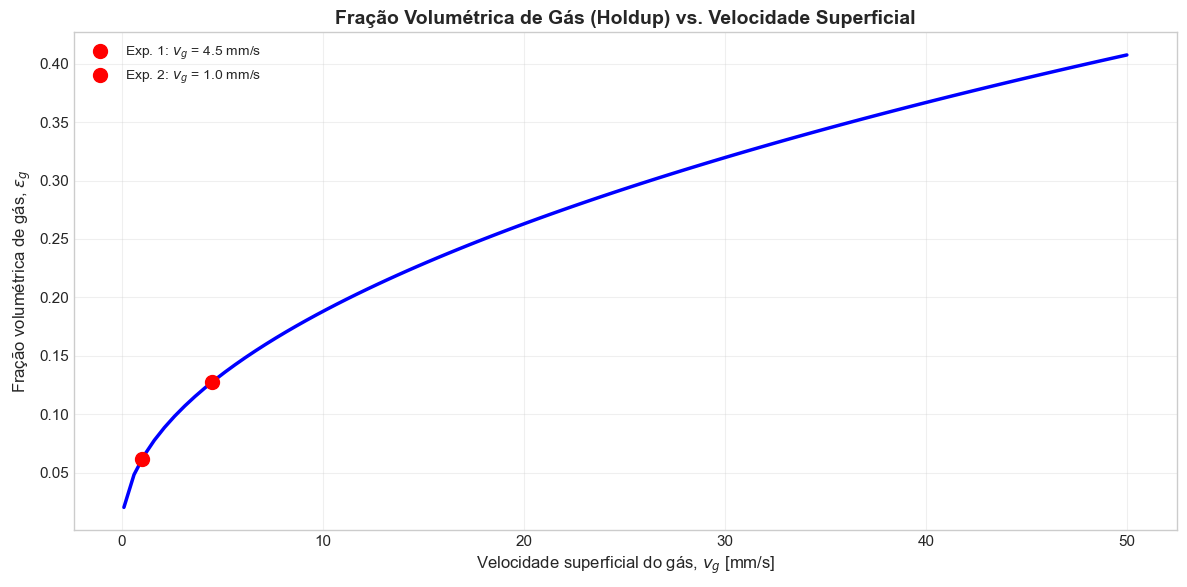

In [23]:
# ============================================================
# GRÁFICO 3: FRAÇÃO VOLUMÉTRICA DE GÁS (HOLDUP)
# ============================================================

# Calcular holdup para diferentes velocidades superficiais
v_g_range = np.linspace(1e-4, 0.05, 100)

# Número de Euler modificado
U_range = v_g_range * (rho_l**2 / ((rho_l - rho_g) * g_grav * sigma))**0.25

# Fração volumétrica de gás (correlação de Kumar)
eps_g_range = 0.728 * U_range**0.485 - 0.095 * U_range**3

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(v_g_range * 1000, eps_g_range, 'b-', linewidth=2.5)

# Marcar velocidades dos experimentos
for nome, exp in experimentos.items():
    U_exp = exp['v_g'] * (rho_l**2 / ((rho_l - rho_g) * g_grav * sigma))**0.25
    eps_exp = 0.728 * U_exp**0.485 - 0.095 * U_exp**3
    ax.plot(exp['v_g'] * 1000, eps_exp, 'ro', markersize=10,
            label=f'{nome}: $v_g$ = {exp["v_g"]*1000:.1f} mm/s')

ax.set_xlabel('Velocidade superficial do gás, $v_g$ [mm/s]', fontsize=12)
ax.set_ylabel('Fração volumétrica de gás, $\\varepsilon_g$', fontsize=12)
ax.set_title('Fração Volumétrica de Gás (Holdup) vs. Velocidade Superficial',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 📈 Seção 8: Análise Quantitativa

In [24]:
# ============================================================
# TABELA COMPARATIVA DOS EXPERIMENTOS
# ============================================================

dados_tabela = []

for nome, res in resultados.items():
    exp = res['params']
    C_final = res['C_arr'][-1]
    deplecao = (1 - C_final / exp['C_b0']) * 100

    # Holdup
    U_exp = exp['v_g'] * (rho_l**2 / ((rho_l - rho_g) * g_grav * sigma))**0.25
    eps_exp = 0.728 * U_exp**0.485 - 0.095 * U_exp**3

    # Taxa inicial de depleção
    Gamma_inicial = isoterma_duas_camadas(exp['C_b0'], K1_iso, K2_iso, a_hat, lambda_iso)
    taxa_inicial = -6.0 * exp['v_g'] * Gamma_inicial / (d_b * exp['H'])

    dados_tabela.append({
        'Experimento': nome,
        '$C_{b0}$ [g/m³]': f'{exp["C_b0"]:.0f}',
        '$H$ [m]': f'{exp["H"]:.2f}',
        '$v_g$ [mm/s]': f'{exp["v_g"]*1000:.1f}',
        '$\\varepsilon_g$ [-]': f'{eps_exp:.4f}',
        '$\\Gamma(C_{b0})$ [mg/m²]': f'{Gamma_inicial:.3f}',
        'Taxa inicial [g/(m³·s)]': f'{abs(taxa_inicial):.4f}',
        '$C_b(t_f)$ [g/m³]': f'{C_final:.2f}',
        'Depleção [%]': f'{deplecao:.1f}'
    })

df_comp = pd.DataFrame(dados_tabela)
display(Markdown('### Tabela Comparativa dos Experimentos'))
display(Markdown(df_comp.to_markdown(index=False)))

### Tabela Comparativa dos Experimentos

| Experimento   |   $C_{b0}$ [g/m³] |   $H$ [m] |   $v_g$ [mm/s] |   $\varepsilon_g$ [-] |   $\Gamma(C_{b0})$ [mg/m²] |   Taxa inicial [g/(m³·s)] |   $C_b(t_f)$ [g/m³] |   Depleção [%] |
|:--------------|------------------:|----------:|---------------:|----------------------:|---------------------------:|--------------------------:|--------------------:|---------------:|
| Exp. 1        |              1000 |       0.5 |            4.5 |                0.1276 |                     13.427 |                  241.679  |              580.15 |           42   |
| Exp. 2        |                10 |       0.8 |            1   |                0.0615 |                      2.731 |                    6.8279 |                2.44 |           75.6 |

---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade da depleção à velocidade superficial do gás e à altura da coluna.

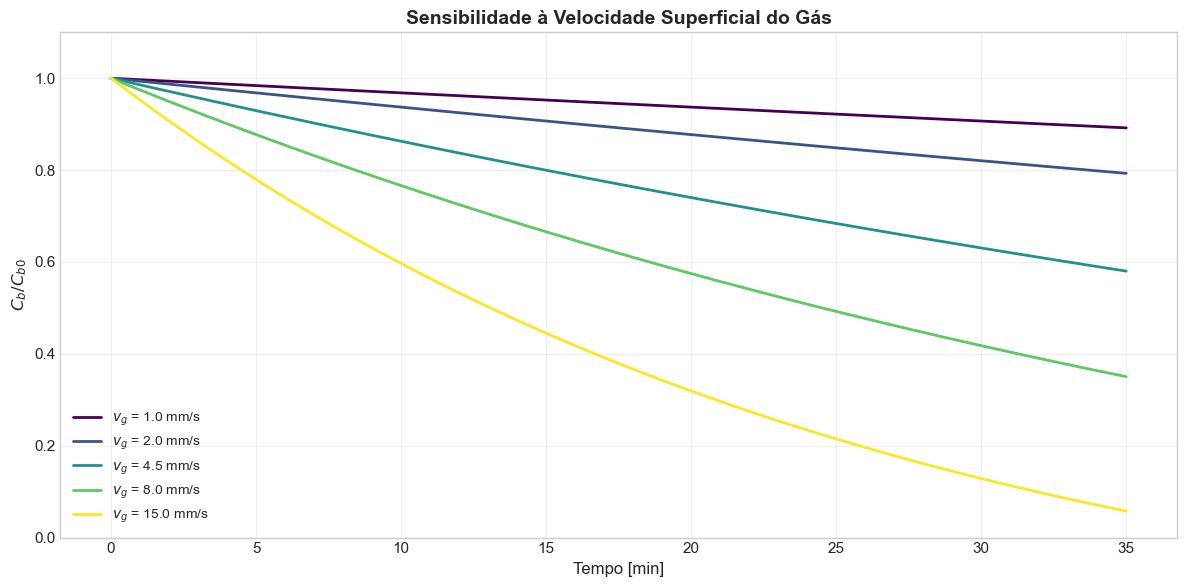

📊 Sensibilidade à velocidade superficial do gás:
  • Aumentar v_g acelera a depleção (mais interface renovada por unidade de tempo)
  • Porém, v_g muito alta pode causar coalescência de bolhas e perda de eficiência


In [25]:
# ============================================================
# SENSIBILIDADE: VELOCIDADE SUPERFICIAL DO GÁS
# ============================================================

# Variar v_g mantendo C_b0 = 1000, H = 0.5
v_g_sens = [1e-3, 2e-3, 4.5e-3, 8e-3, 15e-3]
t_final_sens = 2100.0

fig, ax = plt.subplots(figsize=(12, 6))

cores = plt.cm.viridis(np.linspace(0, 1, len(v_g_sens)))

for i, v_g_val in enumerate(v_g_sens):
    t_arr, C_arr = solver_rk2(1000.0, t_final_sens, dt_sim, v_g_val, d_b, 0.5)
    ax.plot(t_arr / 60, C_arr / 1000.0, color=cores[i], linewidth=2,
            label=f'$v_g$ = {v_g_val*1000:.1f} mm/s')

ax.set_xlabel('Tempo [min]', fontsize=12)
ax.set_ylabel('$C_b / C_{b0}$', fontsize=12)
ax.set_title('Sensibilidade à Velocidade Superficial do Gás',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

print('📊 Sensibilidade à velocidade superficial do gás:')
print('  • Aumentar v_g acelera a depleção (mais interface renovada por unidade de tempo)')
print('  • Porém, v_g muito alta pode causar coalescência de bolhas e perda de eficiência')

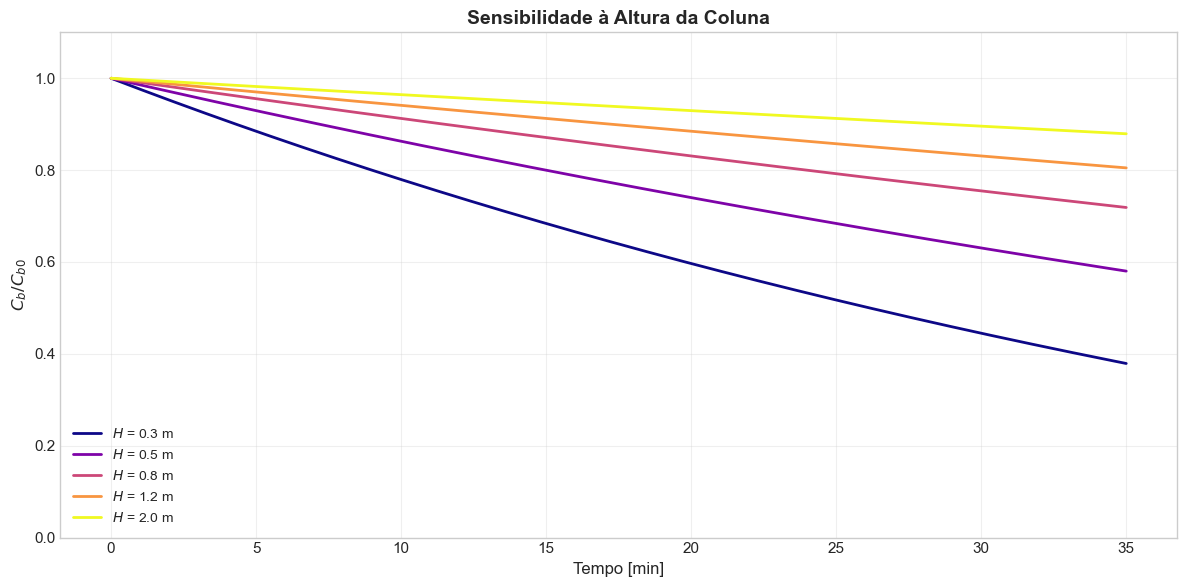

📊 Sensibilidade à altura da coluna:
  • Aumentar H reduz a taxa de depleção (mais volume para tratar)
  • Porém, colunas mais altas proporcionam maior tempo de contato


In [26]:
# ============================================================
# SENSIBILIDADE: ALTURA DA COLUNA
# ============================================================

# Variar H mantendo C_b0 = 1000, v_g = 4.5e-3
H_sens = [0.3, 0.5, 0.8, 1.2, 2.0]

fig, ax = plt.subplots(figsize=(12, 6))

cores = plt.cm.plasma(np.linspace(0, 1, len(H_sens)))

for i, H_val in enumerate(H_sens):
    t_arr, C_arr = solver_rk2(1000.0, t_final_sens, dt_sim, 4.5e-3, d_b, H_val)
    ax.plot(t_arr / 60, C_arr / 1000.0, color=cores[i], linewidth=2,
            label=f'$H$ = {H_val:.1f} m')

ax.set_xlabel('Tempo [min]', fontsize=12)
ax.set_ylabel('$C_b / C_{b0}$', fontsize=12)
ax.set_title('Sensibilidade à Altura da Coluna',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

print('📊 Sensibilidade à altura da coluna:')
print('  • Aumentar H reduz a taxa de depleção (mais volume para tratar)')
print('  • Porém, colunas mais altas proporcionam maior tempo de contato')

---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Mecanismo de depleção:** A BSA se adsorve na interface gás-líquico das bolhas ascendentes. Quando as bolhas atingem o topo e formam espuma, a proteína adsorvida é removida do sistema. A taxa de depleção é proporcional à área interfacial disponível ($6/d_b$) e ao excesso superficial $\Gamma$.

2. **Efeito da concentração inicial:** No Exp. 1 ($C_{b0} = 1000$ g/m³), a alta concentração permite ocupação significativa da segunda camada, e a depleção é governada principalmente por $K_2$ e $\hat{a}$. No Exp. 2 ($C_{b0} = 10$ g/m³), a ocupação da segunda camada é pequena e a depleção reflete as interações laterais da primeira camada ($\lambda$).

3. **Efeito da velocidade superficial:** Aumentar $v_g$ eleva a área interfacial renovada por unidade de tempo (Eq. de depleção), produzindo depleção mais acentuada. Porém, $v_g$ muito alta pode causar coalescência de bolhas e redução da área específica.

4. **Isoterma de duas camadas vs. Langmuir:** A isoterma de duas camadas é necessária para macromoléculas como a BSA, que podem formar múltiplas camadas na interface. A isoterma de Langmuir (uma camada) subestimaria a capacidade de adsorção em altas concentrações.

### Limitações do Modelo

- **Sem dispersão axial:** O modelo assume mistura perfeita no bulk. Na prática, há gradientes de concentração ao longo da coluna.
- **Sem dessorção:** Assume-se que a espuma é removida continuamente e não há retorno de BSA ao bulk.
- **Diâmetro de bolha constante:** Na prática, $d_b$ varia com a posição na coluna e com a velocidade do gás.
- **Isoterma de equilíbrio:** Assume-se que a adsorção atinge o equilíbrio instantaneamente. Para proteínas grandes, a cinética de adsorção pode ser limitante.
- **Sem efeito de pH e força iônica:** A adsorção de proteínas é fortemente afetada pelo pH e pela presença de sais.

### Aplicações Práticas

- **Indústria alimentícia:** Recuperação de proteínas de soro de leite, clara de ovo e subprodutos da indústria de carnes.
- **Indústria farmacêutica:** Concentração e purificação de proteínas terapêuticas.
- **Tratamento de efluentes:** Remoção de surfactantes e tensoativos de águas residuais.
- **Biotecnologia:** Separação de enzimas e anticorpos.

### Conexão com a Teoria

> 📖 **Referência:** A isoterma de duas camadas e o modelo de depleção são descritos em Lugon Jr., Silva Neto & Santana (2009) e Lugon Jr. et al. (2026), Cap. 12, Seções 12.2–12.3. A equação de Gibbs para excesso superficial segue Lugon Jr. et al. (2026), Cap. 12, Seção 12.1. A provocação sobre o problema inverso (estimação de $K_2$, $\hat{a}$, $\lambda$) é tratada no Apêndice de Problemas Inversos.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 12](../notebooks/12_Adsorcao_Interfacial.ipynb)
- [💡 Caso 12.2 — Separação Cromatográfica](EC_12_02_Separacao_Cromatografica_Glicose_Frutose.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 12.1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>